# Lab 28-05 · Curves Behind Single-Point Claims

Companion to [chapter 28-05](../../chapters/28-05-question-banks-analog-rf-power-packaging-embedded.md). Every part asks you to **predict first**, then run. Device figures come from the chapter's cited sources; other parameters are its assumptions.

In [1]:
import sys, math
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, '.')
import bankcheck as bc

## Part 1 · A claim against the frontier

Example 28-05.1: 66 dB SNDR at 1 GS/s. Published best at 1 GS/s or faster: 68.2 dB SNDR at 15.3 mW [R-336].

**Predict:** the claim's Schreier figure at 5 mW.

claim at 5 mW: 176.0 dB
published point: 173.3 dB
ceiling at 300 K: 191.8 dB


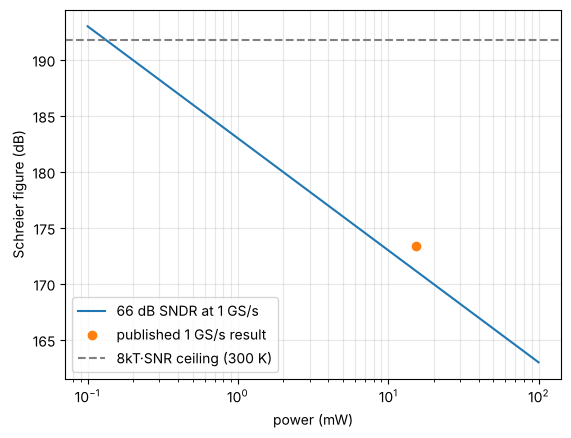

In [2]:
print(f"claim at 5 mW: {bc.fom_schreier(66, 5e8, 0.005):.1f} dB")
print(f"published point: {bc.fom_schreier(68.2, 5e8, 0.0153):.1f} dB")
print(f"ceiling at 300 K: {bc.schreier_ceiling(300):.1f} dB")
p = np.logspace(-4, -1, 100)
plt.semilogx(1e3*p, [bc.fom_schreier(66, 5e8, x) for x in p], label='66 dB SNDR at 1 GS/s')
plt.plot([15.3], [bc.fom_schreier(68.2, 5e8, 0.0153)], 'o', label='published 1 GS/s result')
plt.axhline(bc.schreier_ceiling(300), color='grey', ls='--', label='8kT·SNR ceiling (300 K)')
plt.xlabel('power (mW)'); plt.ylabel('Schreier figure (dB)'); plt.legend(); plt.grid(True, which='both', alpha=0.3); plt.show()

## Part 2 · Jitter against input frequency

**Predict:** the highest input frequency at which a 50 fs clock allows 60 dB, and the SNR at 2 GHz.

highest input for 60 dB: 3.18 GHz
SNR at 2 GHz: 64.0 dB


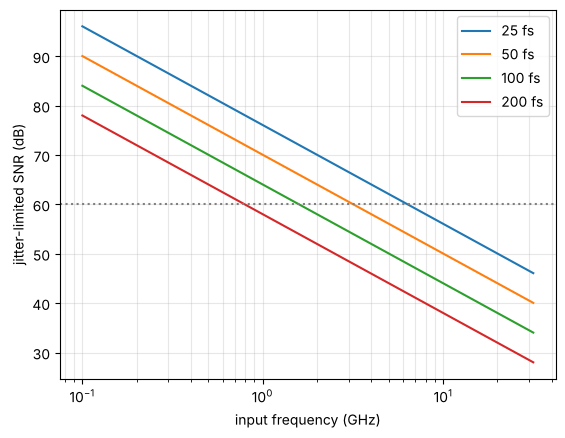

In [3]:
f_max = 10**(-60/20) / (2*math.pi*50e-15)
print(f"highest input for 60 dB: {f_max/1e9:.2f} GHz")
print(f"SNR at 2 GHz: {bc.snr_jitter(2e9, 50e-15):.1f} dB")
f = np.logspace(8, 10.5, 100)
for sig in (25e-15, 50e-15, 100e-15, 200e-15):
    plt.semilogx(f/1e9, [bc.snr_jitter(x, sig) for x in f], label=f'{sig*1e15:.0f} fs')
plt.axhline(60, color='grey', ls=':')
plt.xlabel('input frequency (GHz)'); plt.ylabel('jitter-limited SNR (dB)'); plt.legend(); plt.grid(True, which='both', alpha=0.3); plt.show()

## Part 3 · Efficiency against back-off

**Predict:** the ideal Doherty and class-B efficiencies at 9 dB back-off.

Doherty: 55.7%, class B: 27.9%
Doherty dip at two-thirds amplitude: 69.8%


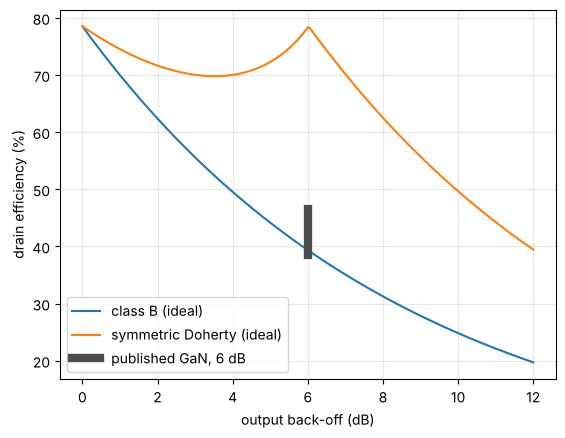

In [4]:
print(f"Doherty: {100*bc.eff_doherty(9):.1f}%, class B: {100*bc.eff_class_b(9):.1f}%")
dip = bc.eff_doherty(-20*math.log10(2/3))
print(f"Doherty dip at two-thirds amplitude: {100*dip:.1f}%")
bo = np.linspace(0, 12, 241)
plt.plot(bo, [100*bc.eff_class_b(x) for x in bo], label='class B (ideal)')
plt.plot(bo, [100*bc.eff_doherty(x) for x in bo], label='symmetric Doherty (ideal)')
plt.plot([6, 6], [38.5, 46.5], lw=6, color='0.3', label='published GaN, 6 dB')
plt.xlabel('output back-off (dB)'); plt.ylabel('drain efficiency (%)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 4 · Battery life against duty cycle

Example 28-05.6: sleep 2.21 µA (4.71 µA at 85 °C); MCU at 32 MHz for 2 ms per wake; radio TX 5.1 mA and RX 5.3 mA for 1 ms each every 10 s; CR2032 225 mAh.

**Predict:** average current and life if the MCU wakes every 10 s.

3.90 µA, 6.59 years


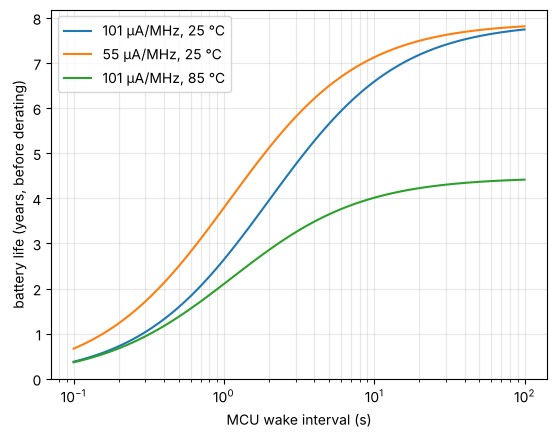

In [5]:
def node(period, ua_per_mhz=101, sleep=2.21):
    ev = [(ua_per_mhz*32, 0.002, period), (5100, 0.001, 10), (5300, 0.001, 10)]
    return bc.avg_current_ua(sleep, ev)
i10 = node(10)
print(f"{i10:.2f} µA, {bc.battery_years(225, i10):.2f} years")
T = np.logspace(-1, 2, 100)
for kw, lab in ((dict(), '101 µA/MHz, 25 °C'), (dict(ua_per_mhz=55), '55 µA/MHz, 25 °C'), (dict(sleep=4.71), '101 µA/MHz, 85 °C')):
    plt.semilogx(T, [bc.battery_years(225, node(t, **kw)) for t in T], label=lab)
plt.xlabel('MCU wake interval (s)'); plt.ylabel('battery life (years, before derating)'); plt.legend(); plt.grid(True, which='both', alpha=0.3); plt.show()